# RQ4 — Temporal Robustness of Prompt Refinement

This notebook evaluates whether the performance gain produced by the final
`code_disambiguation` prompt differs between the pre- and post-cutoff
partitions.

The design is a fully paired \(2\times2\) repeated-measures experiment:

- **Dataset:** pre-cutoff versus post-cutoff;
- **Prompt:** baseline versus refined (`code_disambiguation`);
- **Statistical unit:** project (\(N=30\));
- **Outcome:** project-level Macro-F1.

For each project,

\[
G_d = \mathrm{MacroF1}_{\mathrm{refined},d}
      - \mathrm{MacroF1}_{\mathrm{baseline},d},
\]

and the interaction contrast is

\[
D = G_{\mathrm{post}} - G_{\mathrm{pre}}.
\]

A positive \(D\) means that refinement improved more in the post-cutoff
partition. A significant positive interaction would be consistent with the
operational prompt-overfitting hypothesis. A non-significant interaction does
not establish equivalence.

In [1]:
from pathlib import Path
import textwrap

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.special import gamma
from scipy.stats import f as f_distribution
from scipy.stats import rankdata, shapiro, t, ttest_rel, wilcoxon

DATA_PATH = Path("overfitting.csv")
EXPECTED_PROJECTS = 30
REQUIRED_COLUMNS = [
    "Project",
    "baseline_pre_cutoff",
    "refined_pre_cutoff",
    "baseline_post_cutoff",
    "refined_post_cutoff",
]

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Expected the project-level metric file at {DATA_PATH.resolve()}."
    )

df_raw = pd.read_csv(DATA_PATH, sep=";", decimal=",")
df_raw.columns = df_raw.columns.str.strip()

missing_columns = [c for c in REQUIRED_COLUMNS if c not in df_raw.columns]
unexpected_columns = [c for c in df_raw.columns if c not in REQUIRED_COLUMNS]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")
if unexpected_columns:
    raise ValueError(f"Unexpected columns: {unexpected_columns}")
if len(df_raw) != EXPECTED_PROJECTS:
    raise ValueError(
        f"Expected {EXPECTED_PROJECTS} projects, found {len(df_raw)}."
    )
if df_raw["Project"].duplicated().any():
    duplicates = (
        df_raw.loc[df_raw["Project"].duplicated(), "Project"]
        .astype(str)
        .tolist()
    )
    raise ValueError(f"Duplicate project identifiers: {duplicates}")

metric_columns = REQUIRED_COLUMNS[1:]
for column in metric_columns:
    df_raw[column] = pd.to_numeric(df_raw[column], errors="raise")

if df_raw[metric_columns].isna().any().any():
    raise ValueError("Missing Macro-F1 values are not allowed.")

invalid_values = (df_raw[metric_columns] < 0) | (df_raw[metric_columns] > 1)
if invalid_values.any().any():
    raise ValueError("Macro-F1 values outside [0, 1] were found.")

df_clean = (
    df_raw[REQUIRED_COLUMNS]
    .sort_values("Project")
    .set_index("Project")
)

print(f"Input: {DATA_PATH.resolve()}")
print(f"Paired projects: {len(df_clean)}")
print("Validation: OK — 30 unique projects, four complete conditions, values in [0, 1].")
display(df_clean.head())

Input: /mnt/data/rq4_overfitting_notebook_final/overfitting.csv
Paired projects: 30
Validation: OK — 30 unique projects, four complete conditions, values in [0, 1].


,baseline_pre_cutoff,refined_pre_cutoff,baseline_post_cutoff,refined_post_cutoff
Project,,,,
cargo/clap,0.649988,0.643258,0.632440,0.651346
go/google-cloud-go,0.469460,0.498847,0.455137,0.436634
npm/angular,0.349377,0.367307,0.336819,0.520908
npm/ant-design,0.378194,0.332286,0.428439,0.355520
npm/biome,0.546955,0.514454,0.464437,0.481722


## Confirmatory interaction analysis

The confirmatory hypothesis concerns the project-level difference in prompt
gains, \(D = G_{\mathrm{post}}-G_{\mathrm{pre}}\).

Because each repeated-measures factor has only two levels, sphericity is
satisfied by construction.

- If Shapiro–Wilk does not reject normality for \(D\), use the parametric
  Dataset × Prompt interaction and its equivalent paired \(t\)-contrast.
- Otherwise, use a two-sided Wilcoxon signed-rank test on \(D\).

For the parametric route, the notebook reports Hedges' \(g_{av}\) and
generalized \(\eta_G^2\). The equivalence \(F=t^2\) is checked numerically.

In [2]:
def _format_decimal(value, digits=3):
    text = f"{float(value):.{digits}f}"
    if text.startswith("0."):
        return text[1:]
    if text.startswith("-0."):
        return "-" + text[2:]
    return text


def _format_p_markdown(p_value):
    p_value = float(p_value)
    if p_value < 0.001:
        return r"$p<.001$"
    return f"$p={_format_decimal(p_value)}$"


def _condition_descriptives(data):
    n = len(data)
    critical_t = t.ppf(0.975, df=n - 1)
    rows = []

    for dataset, baseline_column, refined_column in [
        ("Pre-cutoff", "baseline_pre_cutoff", "refined_pre_cutoff"),
        ("Post-cutoff", "baseline_post_cutoff", "refined_post_cutoff"),
    ]:
        gain = data[refined_column] - data[baseline_column]
        se = gain.sem()
        rows.append({
            "Dataset": dataset,
            "N": n,
            "Baseline Mean": data[baseline_column].mean(),
            "Baseline SD": data[baseline_column].std(ddof=1),
            "Refined Mean": data[refined_column].mean(),
            "Refined SD": data[refined_column].std(ddof=1),
            "Mean Gain": gain.mean(),
            "Gain SD": gain.std(ddof=1),
            "Gain CI95 Lower": gain.mean() - critical_t * se,
            "Gain CI95 Upper": gain.mean() + critical_t * se,
            "Projects Improved": int((gain > 0).sum()),
            "Projects Worsened": int((gain < 0).sum()),
            "Projects Unchanged": int((gain == 0).sum()),
        })

    return pd.DataFrame(rows).set_index("Dataset")


def _hedges_g_av(x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    average_sd = np.sqrt(
        (np.var(x, ddof=1) + np.var(y, ddof=1)) / 2
    )
    if np.isclose(average_sd, 0):
        return 0.0

    d_av = (np.mean(x) - np.mean(y)) / average_sd
    df = 2 * len(x) - 2
    correction = (
        gamma(df / 2)
        / (np.sqrt(df / 2) * gamma((df - 1) / 2))
    )
    return float(d_av * correction)


def _rank_biserial_from_differences(differences):
    differences = np.asarray(differences, dtype=float)
    differences = differences[~np.isclose(differences, 0)]

    if len(differences) == 0:
        return 0.0

    ranks = rankdata(np.abs(differences))
    positive = ranks[differences > 0].sum()
    negative = ranks[differences < 0].sum()
    return float((positive - negative) / (positive + negative))


def _rm_anova_2x2(data):
    array = np.empty((len(data), 2, 2), dtype=float)
    array[:, 0, 0] = data["baseline_pre_cutoff"].to_numpy()
    array[:, 0, 1] = data["refined_pre_cutoff"].to_numpy()
    array[:, 1, 0] = data["baseline_post_cutoff"].to_numpy()
    array[:, 1, 1] = data["refined_post_cutoff"].to_numpy()

    n, n_dataset_levels, n_prompt_levels = array.shape
    grand_mean = array.mean()
    subject_means = array.mean(axis=(1, 2))
    dataset_means = array.mean(axis=(0, 2))
    prompt_means = array.mean(axis=(0, 1))
    cell_means = array.mean(axis=0)
    subject_dataset_means = array.mean(axis=2)
    subject_prompt_means = array.mean(axis=1)

    ss_total = np.square(array - grand_mean).sum()
    ss_subject = (
        n_dataset_levels * n_prompt_levels
        * np.square(subject_means - grand_mean).sum()
    )
    ss_dataset = (
        n * n_prompt_levels
        * np.square(dataset_means - grand_mean).sum()
    )
    ss_prompt = (
        n * n_dataset_levels
        * np.square(prompt_means - grand_mean).sum()
    )
    ss_interaction = (
        n * np.square(
            cell_means
            - dataset_means[:, None]
            - prompt_means[None, :]
            + grand_mean
        ).sum()
    )
    ss_subject_dataset = (
        n_prompt_levels * np.square(
            subject_dataset_means
            - subject_means[:, None]
            - dataset_means[None, :]
            + grand_mean
        ).sum()
    )
    ss_subject_prompt = (
        n_dataset_levels * np.square(
            subject_prompt_means
            - subject_means[:, None]
            - prompt_means[None, :]
            + grand_mean
        ).sum()
    )
    ss_subject_interaction = (
        ss_total
        - ss_subject
        - ss_dataset
        - ss_prompt
        - ss_interaction
        - ss_subject_dataset
        - ss_subject_prompt
    )

    generalized_noise = (
        ss_subject
        + ss_subject_dataset
        + ss_subject_prompt
        + ss_subject_interaction
    )

    rows = []
    for source, ss_effect, ss_error in [
        ("Dataset", ss_dataset, ss_subject_dataset),
        ("Prompt", ss_prompt, ss_subject_prompt),
        ("Dataset × Prompt", ss_interaction, ss_subject_interaction),
    ]:
        df1 = 1
        df2 = n - 1
        ms_effect = ss_effect
        ms_error = ss_error / df2
        f_statistic = ms_effect / ms_error
        p_value = f_distribution.sf(f_statistic, df1, df2)
        eta_g2 = ss_effect / (ss_effect + generalized_noise)

        rows.append({
            "Source": source,
            "SS": ss_effect,
            "df1": df1,
            "df2": df2,
            "MS": ms_effect,
            "F": f_statistic,
            "p": p_value,
            "eta_G2": eta_g2,
        })

    return pd.DataFrame(rows)


def run_overfitting_analysis(data, alpha=0.05):
    pre_gain = data["refined_pre_cutoff"] - data["baseline_pre_cutoff"]
    post_gain = data["refined_post_cutoff"] - data["baseline_post_cutoff"]
    difference_in_gains = post_gain - pre_gain

    gains = pd.DataFrame({
        "Pre-cutoff gain": pre_gain,
        "Post-cutoff gain": post_gain,
        "Difference in gains": difference_in_gains,
    })

    normality_rows = []
    for variable in gains.columns:
        statistic, p_value = shapiro(gains[variable])
        normality_rows.append({
            "Variable": variable,
            "N": int(gains[variable].notna().sum()),
            "W": float(statistic),
            "p": float(p_value),
            "Normality not rejected": bool(p_value >= alpha),
        })

    normality = pd.DataFrame(normality_rows).set_index("Variable")
    route = (
        "parametric"
        if bool(normality.loc[
            "Difference in gains", "Normality not rejected"
        ])
        else "non-parametric"
    )

    n = len(data)
    mean_difference = difference_in_gains.mean()
    sd_difference = difference_in_gains.std(ddof=1)

    if route == "parametric":
        statistic, p_value = ttest_rel(post_gain, pre_gain)
        se = difference_in_gains.sem()
        critical_t = t.ppf(0.975, df=n - 1)

        direct_contrast = {
            "Test": "Paired t-test on difference in gains",
            "Statistic name": "t",
            "Statistic": float(statistic),
            "df": n - 1,
            "p": float(p_value),
            "Effect name": "Hedges' g_av",
            "Effect": _hedges_g_av(post_gain.to_numpy(), pre_gain.to_numpy()),
            "Mean difference in gains": float(mean_difference),
            "SD difference in gains": float(sd_difference),
            "CI95 Lower": float(mean_difference - critical_t * se),
            "CI95 Upper": float(mean_difference + critical_t * se),
            "Significant": bool(p_value < alpha),
        }

        anova = _rm_anova_2x2(data)
        interaction_row = anova.loc[
            anova["Source"] == "Dataset × Prompt"
        ].iloc[0]

        interaction = {
            "Test": "Dataset × Prompt interaction",
            "Statistic name": "F",
            "Statistic": float(interaction_row["F"]),
            "df1": int(interaction_row["df1"]),
            "df2": int(interaction_row["df2"]),
            "p": float(interaction_row["p"]),
            "Effect name": "eta_G_squared",
            "Effect": float(interaction_row["eta_G2"]),
            "Significant": bool(interaction_row["p"] < alpha),
        }

        if not np.isclose(
            interaction["Statistic"],
            direct_contrast["Statistic"] ** 2,
            rtol=1e-10,
            atol=1e-12,
        ):
            raise ValueError("Internal consistency check failed: F != t².")
    else:
        if np.allclose(difference_in_gains, 0):
            statistic = 0.0
            p_value = 1.0
            effect = 0.0
        else:
            test = wilcoxon(
                difference_in_gains.to_numpy(),
                alternative="two-sided",
                zero_method="wilcox",
            )
            statistic = float(test.statistic)
            p_value = float(test.pvalue)
            effect = _rank_biserial_from_differences(
                difference_in_gains.to_numpy()
            )

        direct_contrast = {
            "Test": "Wilcoxon test on difference in gains",
            "Statistic name": "W",
            "Statistic": statistic,
            "df": np.nan,
            "p": p_value,
            "Effect name": "Rank-biserial correlation",
            "Effect": effect,
            "Mean difference in gains": float(mean_difference),
            "SD difference in gains": float(sd_difference),
            "CI95 Lower": np.nan,
            "CI95 Upper": np.nan,
            "Significant": bool(p_value < alpha),
        }
        anova = None
        interaction = None

    descriptives = _condition_descriptives(data)

    print("DESCRIPTIVE PROMPT GAINS")
    display(descriptives.round(3))

    print("NORMALITY OF PAIRED CONTRASTS")
    normality_display = normality.copy()
    normality_display["W"] = normality_display["W"].round(3)
    normality_display["p"] = normality_display["p"].round(3)
    display(normality_display)

    print(f"SELECTED INTERACTION ROUTE: {route}")
    print("DIRECT DIFFERENCE-IN-GAINS CONTRAST")
    display(pd.DataFrame([direct_contrast]).round(3))

    if anova is not None:
        print("TWO-WAY REPEATED-MEASURES ANOVA")
        display(anova.round(3))
        print("DATASET × PROMPT INTERACTION")
        display(pd.DataFrame([interaction]).round(3))

    return {
        "data": data,
        "gains": gains,
        "descriptives": descriptives,
        "normality": normality,
        "route": route,
        "direct_contrast": direct_contrast,
        "anova": anova,
        "interaction": interaction,
        "alpha": alpha,
    }


def generate_overfitting_report(analysis):
    normality = analysis["normality"]
    descriptives = analysis["descriptives"]
    contrast = analysis["direct_contrast"]
    interaction = analysis["interaction"]

    pre_gain = descriptives.loc["Pre-cutoff", "Mean Gain"]
    post_gain = descriptives.loc["Post-cutoff", "Mean Gain"]
    difference = contrast["Mean difference in gains"]
    normality_row = normality.loc["Difference in gains"]

    if analysis["route"] == "parametric":
        eta_text = (
            "<.001"
            if 0 < abs(interaction["Effect"]) < 0.001
            else _format_decimal(interaction["Effect"])
        )
        eta_report = (
            rf"$\\eta_G^2<.001$"
            if 0 < abs(interaction["Effect"]) < 0.001
            else rf"$\\eta_G^2={_format_decimal(interaction['Effect'])}$"
        )
        inference = (
            "Shapiro–Wilk did not reject normality for the "
            "project-level difference-in-gains contrast "
            f"($W={_format_decimal(normality_row['W'])}$, "
            f"{_format_p_markdown(normality_row['p'])}). "
            "The dataset-by-prompt interaction was not significant, "
            f"$F({interaction['df1']},{interaction['df2']})="
            f"{interaction['Statistic']:.3f}$, "
            f"{_format_p_markdown(interaction['p'])}, "
            f"{eta_report}. "
            "The equivalent direct contrast yielded "
            f"$t({int(contrast['df'])})={contrast['Statistic']:.3f}$, "
            f"{_format_p_markdown(contrast['p'])}, "
            rf"Hedges' $g_{{av}}={contrast['Effect']:.3f}$, "
            "with an unadjusted 95% confidence interval of "
            f"[{contrast['CI95 Lower']:.3f}, "
            f"{contrast['CI95 Upper']:.3f}]."
        )
    else:
        inference = (
            "Shapiro–Wilk rejected normality for the "
            "difference-in-gains contrast; the Wilcoxon signed-rank "
            "test was therefore used."
        )

    report = f"""
## RQ4 temporal robustness interpretation generated from current data

The refined prompt produced a mean Macro-F1 gain of {pre_gain:.3f} in the
pre-cutoff partition and {post_gain:.3f} in the post-cutoff partition. The mean
difference between these gains was {difference:.3f}.

{inference}

We found no statistical evidence that the refined prompt's gain differed
between pre- and post-cutoff partitions. This does not demonstrate equivalence
or rule out smaller interaction effects.
"""
    return textwrap.dedent(report)

## Execute the analysis

All results below are generated from the local `overfitting.csv`.

In [3]:
overfitting_analysis = run_overfitting_analysis(df_clean)
display(Markdown(generate_overfitting_report(overfitting_analysis)))

DESCRIPTIVE PROMPT GAINS


,N,Baseline Mean,Baseline SD,Refined Mean,Refined SD,Mean Gain,Gain SD,Gain CI95 Lower,Gain CI95 Upper,Projects Improved,Projects Worsened,Projects Unchanged
Dataset,,,,,,,,,,,,
Pre-cutoff,30,0.458,0.102,0.471,0.108,0.013,0.049,-0.006,0.031,17,13,0
Post-cutoff,30,0.485,0.097,0.503,0.089,0.018,0.063,-0.005,0.041,20,10,0


NORMALITY OF PAIRED CONTRASTS


,N,W,p,Normality not rejected
Variable,,,,
Pre-cutoff gain,30,0.917,0.023,False
Post-cutoff gain,30,0.948,0.150,True
Difference in gains,30,0.973,0.628,True


SELECTED INTERACTION ROUTE: parametric
DIRECT DIFFERENCE-IN-GAINS CONTRAST


...

TWO-WAY REPEATED-MEASURES ANOVA


,Source,SS,df1,df2,MS,F,p,eta_G2
0,Dataset,0.026,1,29,0.026,1.577,0.219,0.023
1,Prompt,0.007,1,29,0.007,3.108,0.088,0.006
2,Dataset × Prompt,0.000,1,29,0.000,0.228,0.637,0.000


DATASET × PROMPT INTERACTION


,Test,Statistic name,Statistic,df1,df2,p,Effect name,Effect,Significant
0,Dataset × Prompt interaction,F,0.228,1,29,0.637,eta_G_squared,0.0,False



## RQ4 temporal robustness interpretation generated from current data

The refined prompt produced a mean Macro-F1 gain of 0.013 in the
pre-cutoff partition and 0.018 in the post-cutoff partition. The mean
difference between these gains was 0.005.

Shapiro–Wilk did not reject normality for the project-level difference-in-gains contrast ($W=.973$, $p=.628$). The dataset-by-prompt interaction was not significant, $F(1,29)=0.228$, $p=.637$, $\\eta_G^2<.001$. The equivalent direct contrast yielded $t(29)=0.477$, $p=.637$, Hedges' $g_{av}=0.091$, with an unadjusted 95% confidence interval of [-0.017, 0.027].

We found no statistical evidence that the refined prompt's gain differed
between pre- and post-cutoff partitions. This does not demonstrate equivalence
or rule out smaller interaction effects.


## Project-level difference in prompt gains

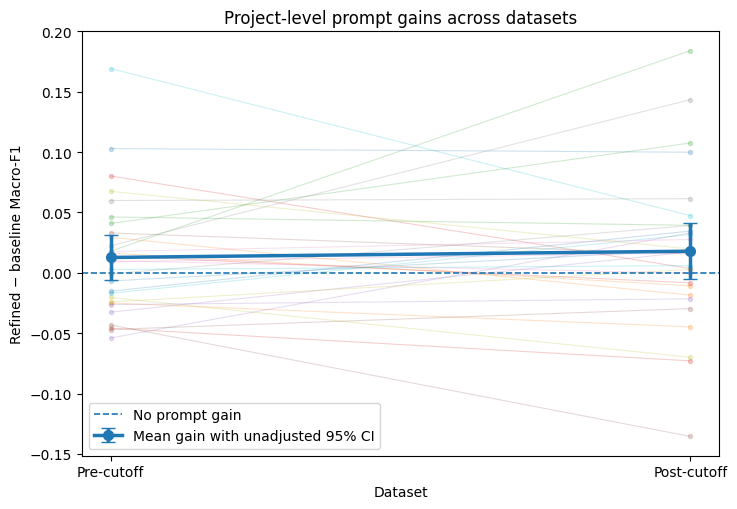

In [4]:
gains = overfitting_analysis["gains"]
positions = np.array([0, 1])
gain_columns = ["Pre-cutoff gain", "Post-cutoff gain"]

means = gains[gain_columns].mean().to_numpy()
standard_errors = gains[gain_columns].sem().to_numpy()
critical_t = t.ppf(0.975, df=len(gains) - 1)

fig, ax = plt.subplots(figsize=(7.5, 5.2))

for _, row in gains[gain_columns].iterrows():
    ax.plot(
        positions,
        row.to_numpy(),
        marker="o",
        alpha=0.22,
        linewidth=0.8,
        markersize=3,
    )

ax.errorbar(
    positions,
    means,
    yerr=critical_t * standard_errors,
    marker="o",
    linewidth=2.5,
    markersize=7,
    capsize=5,
    label="Mean gain with unadjusted 95% CI",
    zorder=5,
)
ax.axhline(0, linestyle="--", linewidth=1.2, label="No prompt gain")

ax.set_xticks(positions, ["Pre-cutoff", "Post-cutoff"])
ax.set_xlabel("Dataset")
ax.set_ylabel("Refined − baseline Macro-F1")
ax.set_title("Project-level prompt gains across datasets")
ax.legend(frameon=True)
fig.tight_layout()
fig.savefig("rq4_overfitting_project_gains.png", dpi=200, bbox_inches="tight")
plt.show()

## Dataset-by-prompt interaction profile

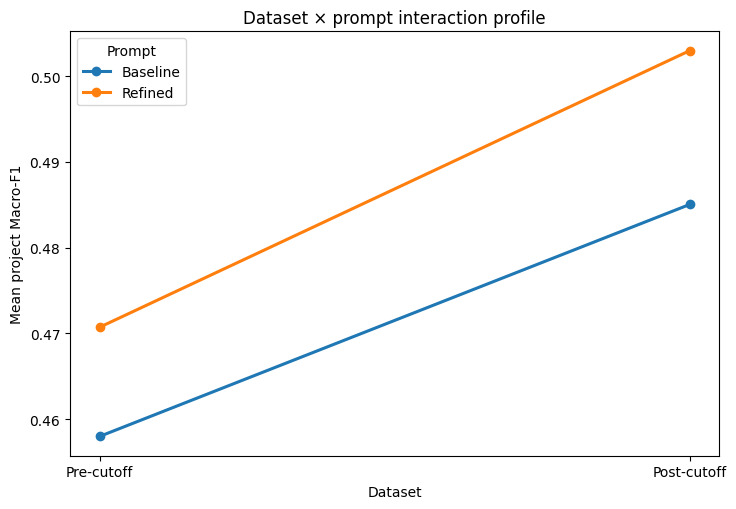

In [5]:
condition_means = pd.DataFrame({
    "Dataset": ["Pre-cutoff", "Pre-cutoff", "Post-cutoff", "Post-cutoff"],
    "Prompt": ["Baseline", "Refined", "Baseline", "Refined"],
    "Mean Macro-F1": [
        df_clean["baseline_pre_cutoff"].mean(),
        df_clean["refined_pre_cutoff"].mean(),
        df_clean["baseline_post_cutoff"].mean(),
        df_clean["refined_post_cutoff"].mean(),
    ],
})

fig, ax = plt.subplots(figsize=(7.5, 5.2))
for prompt in ["Baseline", "Refined"]:
    subset = condition_means.loc[condition_means["Prompt"] == prompt]
    ax.plot(
        subset["Dataset"],
        subset["Mean Macro-F1"],
        marker="o",
        linewidth=2.2,
        label=prompt,
    )

ax.set_xlabel("Dataset")
ax.set_ylabel("Mean project Macro-F1")
ax.set_title("Dataset × prompt interaction profile")
ax.legend(title="Prompt", frameon=True)
fig.tight_layout()
fig.savefig("rq4_overfitting_interaction_profile.png", dpi=200, bbox_inches="tight")
plt.show()

## Reproducibility exports

CSV exports retain full floating-point precision. Three-decimal rounding is used
only in human-readable notebook output and article reporting.

In [6]:
overfitting_analysis["gains"].to_csv(
    "rq4_overfitting_project_gains.csv",
    index_label="Project",
)
overfitting_analysis["descriptives"].to_csv(
    "rq4_overfitting_descriptives.csv",
    index_label="Dataset",
)
overfitting_analysis["normality"].to_csv(
    "rq4_overfitting_normality.csv",
    index_label="Variable",
)
pd.DataFrame([overfitting_analysis["direct_contrast"]]).to_csv(
    "rq4_overfitting_interaction_contrast.csv",
    index=False,
)

if overfitting_analysis["anova"] is not None:
    overfitting_analysis["anova"].to_csv(
        "rq4_overfitting_rm_anova.csv",
        index=False,
    )
    pd.DataFrame([overfitting_analysis["interaction"]]).to_csv(
        "rq4_overfitting_interaction.csv",
        index=False,
    )

print("Reproducibility exports saved.")

Reproducibility exports saved.


## Reproducibility notes

- Reads only the local `overfitting.csv`.
- Performs no network access and no dynamic package installation.
- Requires exactly 30 unique projects and four complete paired Macro-F1 values.
- Performs no decimal-shift repair and no silent complete-case filtering.
- Tests the Dataset × Prompt interaction rather than separate within-partition gains.
- With two levels per factor, no sphericity correction is needed.
- For the parametric route, \(F=t^2\) is checked directly.
- A non-significant interaction does not establish equivalence.